In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib as mpl
from matplotlib.table import Table
from sklearn.linear_model import LinearRegression, TheilSenRegressor, HuberRegressor
from sklearn.metrics import r2_score

In [2]:
def prepapre_data(df, ug_ft, phd_ft, ttt):
    df = df.copy()
    df = df.fillna(0)

    # ------------------------------------------------------------------
    # 1. Clean columns needed for doctoral ratio D
    # ------------------------------------------------------------------
    cols_needed_for_D = [
        "Doctoral Full Time Sum",
        "Doctoral Part Time Sum",
        "Total Tenured/Tenure-Track Faculty"
    ]

    df = df[((df["School Name"] == "Oregon State University") | (df["Doctoral Full Time Sum"] > phd_ft))]
    df = df[((df["School Name"] == "Oregon State University") | (df["Total Tenured/Tenure-Track Faculty"] > ttt))]
    
    for col in cols_needed_for_D:
        df[col] = (
            df[col].astype(str)
              .str.replace(",", "", regex=False)
              .str.strip()
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # ------------------------------------------------------------------
    # 2. Compute doctoral student to faculty ratio D
    # D = full-time doctoral students / TTT faculty
    # ------------------------------------------------------------------
    den = df["Total Tenured/Tenure-Track Faculty"]
    num = df["Doctoral Full Time Sum"]

    df["D"] = (num / den).where(den > 0, np.nan)
    df["D_int"] = df["D"].round().astype("Int64")

    # ------------------------------------------------------------------
    # 3. Year-aware D_AAU benchmark
    # ------------------------------------------------------------------
    d_aau = (
        df.groupby(["Discipline Name", "Year"], as_index=False)["D"]
          .median()
          .rename(columns={"D": "D_AAU"})
    )

    df = df.merge(d_aau, on=["Discipline Name", "Year"], how="left")

    df["D"] = pd.to_numeric(df["D"], errors="coerce")
    df["D_AAU"] = pd.to_numeric(df["D_AAU"], errors="coerce")

    df = df.fillna(0)

    # ------------------------------------------------------------------
    # 4. Compute alpha
    # alpha = 1.0 if D >= D_AAU
    # alpha = 3 - 2 * D / D_AAU if D < D_AAU
    # ------------------------------------------------------------------
    mask = (df["D_AAU"] > 0) & (df["D"] < df["D_AAU"])

    df["alpha"] = .375
    df.loc[mask, "alpha"] = .75 - .375 * (df.loc[mask, "D"] / df.loc[mask, "D_AAU"])

    df["alpha"] = df["alpha"].replace([np.inf, -np.inf], np.nan).fillna(1.0)
    df["alpha"] = df["alpha"].round(3)

    # ------------------------------------------------------------------
    # 5. Clean numeric columns used in student and faculty calculations
    # ------------------------------------------------------------------
    num_cols = [
        "Freshman Full Time Sum",
        "Sophomore Full Time Sum",
        "Junior Full Time Sum",
        "Senior Full Time Sum",
        "Freshman Part Time Sum",
        "Sophomore Part Time Sum",
        "Junior Part Time Sum",
        "Senior Part Time Sum",
        "Masters Full Time Sum",
        "Masters Part Time Sum",
        "Total Tenured/Tenure-Track Faculty",
        "Full Time Teaching Faculty (Non-Tenure)",
        "FTE of Part Time Teaching Faculty (Non-Tenure)",
        "alpha",
    ]

    for col in num_cols:
        df[col] = (
            df[col].astype(str)
                  .str.replace(",", "", regex=False)
                  .str.strip()
        )
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    # ------------------------------------------------------------------
    # 6. Build student terms
    #
    # R = traditional student-to-faculty view.
    #     Includes 1st-, 2nd-, 3rd-, and 4th-year undergraduates.
    #
    # S = SCH-to-teaching-capacity view.
    #     Keeps the bells and whistles.
    #     Excludes 1st- and 2nd-year undergraduates.
    # ------------------------------------------------------------------

    # For R: include all undergraduate years
    df["UG_FT_R"] = (
        df["Freshman Full Time Sum"]
        + df["Sophomore Full Time Sum"]
        + df["Junior Full Time Sum"]
        + df["Senior Full Time Sum"]
    )

    df["UG_PT_R"] = (
        df["Freshman Part Time Sum"]
        + df["Sophomore Part Time Sum"]
        + df["Junior Part Time Sum"]
        + df["Senior Part Time Sum"]
    )

    # For S: exclude 1st- and 2nd-year undergraduates
    df["UG_FT_S"] = (
        df["Junior Full Time Sum"]
        + df["Senior Full Time Sum"]
    )

    df["UG_PT_S"] = (
        df["Junior Part Time Sum"]
        + df["Senior Part Time Sum"]
    )

    df["MS_FT"] = df["Masters Full Time Sum"]
    df["MS_PT"] = df["Masters Part Time Sum"]

    # ------------------------------------------------------------------
    # 7. Faculty terms
    # ------------------------------------------------------------------
    df["TTT"] = df["Total Tenured/Tenure-Track Faculty"]

    df["NTT"] = (
        df["Full Time Teaching Faculty (Non-Tenure)"]
        + df["FTE of Part Time Teaching Faculty (Non-Tenure)"]
    )

    ## filter to remove low-enrolled programs
    df = df[((df["School Name"] == "Oregon State University") | (df["UG_FT_R"] > ug_ft))]
    
    # ------------------------------------------------------------------
    # 8. Raw student-to-faculty ratio R
    #
    # R = all UG students + MS students / TTT + NTT
    # ------------------------------------------------------------------
    df["R_raw_num"] = (
        df["UG_FT_R"]
        + df["UG_PT_R"]
        + df["MS_FT"]
        + df["MS_PT"]
    )

    df["R_raw_den"] = df["TTT"] + df["NTT"]

    df["R_raw"] = np.where(
        df["R_raw_den"] == 0,
        np.nan,
        df["R_raw_num"] / df["R_raw_den"]
    )

    df["R_raw"] = df["R_raw"].replace([np.inf, -np.inf], np.nan)
    df["R_raw"] = df["R_raw"].fillna(0).round(3)
    df["R_raw_int"] = df["R_raw"].round().astype("Int64")

    # ------------------------------------------------------------------
    # 9. SCH numerator for S
    #
    # S numerator = 40UG_FT_S + 29UG_PT_S + 31MS_FT + 25MS_PT
    # ------------------------------------------------------------------
    df["SCH"] = (
        df["UG_FT_S"] * 40
        + df["UG_PT_S"] * 20
        + df["MS_FT"] * 32
        + df["MS_PT"] * 21
    )

    # ------------------------------------------------------------------
    # 10. Teaching capacity denominator for S
    #
    # S denominator = alpha * TTT + 3NTT
    # ------------------------------------------------------------------
    df["S_den"] = (df["alpha"] * df["TTT"]) + (.9 * df["NTT"])

    df["S"] = np.where(
        df["S_den"] == 0,
        np.nan,
        df["SCH"] / df["S_den"]
    )

    df["S"] = df["S"].replace([np.inf, -np.inf], np.nan)
    df["S"] = df["S"].fillna(0).round(3)

    # ------------------------------------------------------------------
    # 11. Backward-compatible aliases
    # ------------------------------------------------------------------
    df["Rs_den"] = df["S_den"]
    df["Rs_SCH"] = df["S"]

    df["Rs_num"] = df["R_raw_num"]
    df["Rs_den_ww"] = df["R_raw_den"]
    df["R_s"] = df["R_raw"]
    df["R_s_int"] = df["R_raw_int"]

    # These aliases keep old filters from breaking, but they now refer to
    # the S-definition undergraduate counts.
    df["UG_FT"] = df["UG_FT_S"]
    df["UG_PT"] = df["UG_PT_S"]

    # ------------------------------------------------------------------
    # 12. Year-aware benchmark for raw R
    # ------------------------------------------------------------------
    r_aau = (
        df.groupby(["Discipline Name", "Year"], as_index=False)["R_raw"]
          .median()
          .rename(columns={"R_raw": "R_AAU"})
    )

    df = df.merge(
        r_aau,
        on=["Discipline Name", "Year"],
        how="left"
    )

    # ------------------------------------------------------------------
    # 13. Year-aware benchmark for S
    # ------------------------------------------------------------------
    s_aau = (
        df.groupby(["Discipline Name", "Year"], as_index=False)["S"]
          .median()
          .rename(columns={"S": "S_AAU"})
    )

    df = df.merge(
        s_aau,
        on=["Discipline Name", "Year"],
        how="left"
    )

    # Backward-compatible benchmark alias
    df["Rs_AAU_SCH"] = df["S_AAU"]

    # ------------------------------------------------------------------
    # 14. Optional filtering
    #
    # Keep OSU out of benchmark comparison set.
    # Apply size threshold only to non-OSU institutions.
    #
    # NOTE:
    # If you re-enable this, decide whether the threshold should be based on:
    #   UG_FT_R = traditional all-UG size
    #   UG_FT_S = S-definition junior/senior-only size
    # ------------------------------------------------------------------
    # if mode == 199:
    #     df = df[
    #         ((df["School Name"] == "Oregon State University") | (df["UG_FT_R"] > 199))
    #     ]
    # else:
    #     df = df[
    #         ((df["School Name"] == "Oregon State University") | (df["UG_FT_R"] > 49))
    #     ]

    return df

In [3]:
def build_program_summary_table(df_osu, df_other, latest_peer_year=2024):
    """
    Build one summary table across programs containing:
      Program, S Q1/Q2/Q3, OSU S, D Q1/Q2/Q3, OSU D

    S values are rounded to integers.
    D values are rounded to one decimal.
    """

    disciplines = sorted(
        set(df_osu["Discipline Name"].dropna().unique())
        | set(df_other["Discipline Name"].dropna().unique())
    )

    rows = []

    for disc in disciplines:
        peer = df_other[
            (df_other["Discipline Name"] == disc) &
            (df_other["Year"] == latest_peer_year)
        ].copy()

        osu = df_osu[
            df_osu["Discipline Name"] == disc
        ].copy()

        if peer.empty or osu.empty:
            continue

        for col in ["S", "D"]:
            peer[col] = pd.to_numeric(peer[col], errors="coerce")
            osu[col] = pd.to_numeric(osu[col], errors="coerce")

        peer = peer.dropna(subset=["S", "D"])
        osu = osu.dropna(subset=["S", "D"])

        if peer.empty or osu.empty:
            continue

        latest_osu_year = int(osu["Year"].max())
        osu_latest = osu[osu["Year"] == latest_osu_year].copy()

        s_q1 = np.nanpercentile(peer["S"], 25)
        s_q2 = np.nanpercentile(peer["S"], 50)
        s_q3 = np.nanpercentile(peer["S"], 75)

        d_q1 = np.nanpercentile(peer["D"], 25)
        d_q2 = np.nanpercentile(peer["D"], 50)
        d_q3 = np.nanpercentile(peer["D"], 75)

        osu_s = float(osu_latest["S"].median())
        osu_d = float(osu_latest["D"].median())

        rows.append({
            "Program": disc,
            "OSU Year": latest_osu_year,
            "S Q1": int(round(s_q1)),
            "S Q2": int(round(s_q2)),
            "S Q3": int(round(s_q3)),
            "OSU S": int(round(osu_s)),
            "D Q1": round(d_q1, 1),
            "D Q2": round(d_q2, 1),
            "D Q3": round(d_q3, 1),
            "OSU D": round(osu_d, 1),
        })

    summary_df = pd.DataFrame(rows)
    return summary_df

In [4]:
def fit_regression_line(
    df,
    x_col,
    y_col="D",
    method="huber",
    min_points=3,
    huber_epsilon=1.35
):
    reg_df = df[[x_col, y_col]].copy()

    reg_df[x_col] = pd.to_numeric(reg_df[x_col], errors="coerce")
    reg_df[y_col] = pd.to_numeric(reg_df[y_col], errors="coerce")

    reg_df = reg_df.replace([np.inf, -np.inf], np.nan)
    reg_df = reg_df.dropna(subset=[x_col, y_col])

    if len(reg_df) < min_points:
        return None

    X = reg_df[[x_col]].values
    y = reg_df[y_col].values

    method = method.lower()

    if method == "ols":
        model = LinearRegression()
        label = "OLS regression"

    elif method == "theil_sen":
        model = TheilSenRegressor(
            random_state=42,
            max_iter=1000
        )
        label = "Theil-Sen regression"

    elif method == "huber":
        model = HuberRegressor(
            epsilon=huber_epsilon,
            max_iter=1000
        )
        label = "Huber regression"

    else:
        raise ValueError(
            "method must be one of: 'ols', 'theil_sen', 'huber'"
        )

    model.fit(X, y)

    if method == "huber":
        m = model.coef_[0]
        b = model.intercept_
    else:
        m = model.coef_[0]
        b = model.intercept_

    y_pred = model.predict(X)

    # Standard R²; can be negative for robust models
    r2 = r2_score(y, y_pred)

    return {
        "model": model,
        "method": method,
        "label": label,
        "x": X.flatten(),
        "y": y,
        "slope": m,
        "intercept": b,
        "r2": r2,
        "n": len(reg_df)
    }

In [5]:
def draw_regression_overlay(
    ax,
    df,
    x_col,
    x_name,
    y_col="D",
    method="huber",
    line_color="black",
    line_width=4,
    show_r2=True
):
    result = fit_regression_line(
        df=df,
        x_col=x_col,
        y_col=y_col,
        method=method
    )

    if result is None:
        return None

    model = result["model"]
    m = result["slope"]
    b = result["intercept"]
    r2 = result["r2"]

    x_min = np.nanmin(result["x"])
    x_max = np.nanmax(result["x"])

    x_line = np.linspace(x_min, x_max, 200).reshape(-1, 1)
    y_line = model.predict(x_line)

    ax.plot(
        x_line,
        y_line,
        color=line_color,
        linewidth=line_width,
        zorder=5
    )

    if show_r2:
        text = (
            f"{result['label']}\n"
            f"D = {m:.4f}{x_name} + {b:.2f}\n"
            f"R² = {r2:.2f}"
        )
    else:
        text = (
            f"{result['label']}\n"
            f"D = {m:.4f}{x_name} + {b:.2f}"
        )

    ax.text(
        0.58,
        0.12,
        text,
        transform=ax.transAxes,
        fontsize=15,
        color="black",
        fontweight="bold",
        ha="left",
        va="bottom",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="none",
            alpha=0.80
        ),
        zorder=10
    )

    return result

In [6]:
def plot(

    disc,

    df_osu,

    df_other,

    latest_peer_year=2024,

    multiply=200,

    add_regression="N",

    regression_method="huber"

):
    # ------------------------------------------------------------------
    # Side-by-side plots:
    #   Left:  R vs D
    #   Right: S vs D
    #
    # Updates implemented:
    #   1. R/S Q1, Q2, Q3 labels use integer values.
    #   2. D Q1, Q2, Q3 labels use one decimal place.
    #   3. Top vertical percentile labels are aligned like the example:
    #        Q1 -> top/right
    #        Q2 -> top/right
    #        Q3 -> top/left
    #   4. Latest OSU S-panel marker label shows coordinates:
    #        (S, D) = (819, 2.6)
    #   5. Peer labels include small dark bullet markers.
    # ------------------------------------------------------------------

    years = [2020, 2021, 2022, 2023, 2024, 2025]

    # ------------------------------------------------------------------
    # Font sizes
    # ------------------------------------------------------------------
    TITLE_FS = 18
    PANEL_TITLE_FS = 16
    AXIS_LABEL_FS = 14
    TICK_FS = 12
    ANNO_FS = 11
    BAND_ANNO_FS = 11
    PEER_LABEL_FS = 8.8
    LEGEND_FS = 11

    # ------------------------------------------------------------------
    # Filter OSU rows
    # ------------------------------------------------------------------
    df_disc = df_osu[
        (df_osu["Discipline Name"] == disc)
        & (df_osu["Year"].isin(years))
    ].copy()

    if df_disc.empty:
        raise ValueError(f"No OSU rows found for {disc} in {years}.")

    # ------------------------------------------------------------------
    # Filter peer rows
    # ------------------------------------------------------------------
    df_peer = df_other[
        (df_other["Discipline Name"] == disc)
        & (df_other["Year"] == latest_peer_year)
    ].copy()

    # ------------------------------------------------------------------
    # Column compatibility
    # ------------------------------------------------------------------
    s_col = "S" if "S" in df_disc.columns else "Rs_SCH"
    s_benchmark_col = "S_AAU" if "S_AAU" in df_disc.columns else "Rs_AAU_SCH"

    r_col = "R_raw" if "R_raw" in df_disc.columns else "R_s"
    r_benchmark_col = "R_AAU" if "R_AAU" in df_disc.columns else None

    peer_label_col = "Peer Label" if "Peer Label" in df_peer.columns else "School Name"

    required_cols = [
        s_col,
        s_benchmark_col,
        r_col,
        "D",
        "D_AAU"
    ]

    if r_benchmark_col is not None:
        required_cols.append(r_benchmark_col)

    # ------------------------------------------------------------------
    # Clean OSU numeric columns
    # ------------------------------------------------------------------
    for c in required_cols:
        if c in df_disc.columns:
            df_disc[c] = pd.to_numeric(df_disc[c], errors="coerce")
            df_disc[c] = df_disc[c].replace([np.inf, -np.inf], np.nan)

    df_disc = df_disc.dropna(subset=[s_col, r_col, "D"])

    if df_disc.empty:
        raise ValueError(f"No valid OSU rows found for {disc} after cleaning.")

    # ------------------------------------------------------------------
    # Clean peer numeric columns
    # ------------------------------------------------------------------
    peer_required_cols = [
        s_col,
        s_benchmark_col,
        r_col,
        "D",
        "D_AAU"
    ]

    if r_benchmark_col is not None:
        peer_required_cols.append(r_benchmark_col)

    for c in peer_required_cols:
        if c in df_peer.columns:
            df_peer[c] = pd.to_numeric(df_peer[c], errors="coerce")
            df_peer[c] = df_peer[c].replace([np.inf, -np.inf], np.nan)

    if not df_peer.empty:
        df_peer = df_peer.dropna(subset=[s_col, r_col, "D"])

    # ------------------------------------------------------------------
    # One OSU row per year
    # ------------------------------------------------------------------
    rows = []

    for yr in years:
        sub = df_disc[df_disc["Year"] == yr].copy()

        if sub.empty:
            continue

        S_yr = float(sub[s_col].median())
        R_yr = float(sub[r_col].median())
        D_yr = float(sub["D"].median())

        D_AAU_vals = sub["D_AAU"].dropna().unique()
        D_AAU_yr = (
            float(D_AAU_vals[0])
            if len(D_AAU_vals)
            else float(sub["D"].median())
        )

        S_AAU_vals = sub[s_benchmark_col].dropna().unique()
        S_AAU_yr = (
            float(S_AAU_vals[0])
            if len(S_AAU_vals)
            else float(sub[s_col].median())
        )

        if r_benchmark_col is not None and r_benchmark_col in sub.columns:
            R_AAU_vals = sub[r_benchmark_col].dropna().unique()
            R_AAU_yr = (
                float(R_AAU_vals[0])
                if len(R_AAU_vals)
                else float(sub[r_col].median())
            )
        else:
            R_AAU_yr = float(sub[r_col].median())

        rows.append({
            "Year": yr,
            "S": S_yr,
            "R": R_yr,
            "D": D_yr,
            "D_AAU": D_AAU_yr,
            "S_AAU": S_AAU_yr,
            "R_AAU": R_AAU_yr
        })

    plot_df = pd.DataFrame(rows).sort_values("Year")

    if plot_df.empty:
        raise ValueError(f"No year-level OSU summaries could be created for {disc}.")

    # ------------------------------------------------------------------
    # Latest OSU year and benchmark values
    # ------------------------------------------------------------------
    latest_year = int(plot_df["Year"].max())
    latest_row = plot_df.loc[plot_df["Year"].idxmax()]

    D_latest = float(latest_row["D_AAU"])
    R_latest_benchmark = float(latest_row["R_AAU"])
    S_latest_benchmark = float(latest_row["S_AAU"])

    # ------------------------------------------------------------------
    # Peer D Q1-Q3
    # ------------------------------------------------------------------
    if not df_peer.empty and df_peer["D"].notna().any():
        D_q25 = float(np.nanpercentile(df_peer["D"], 25))
        D_q75 = float(np.nanpercentile(df_peer["D"], 75))
    else:
        D_q25 = float(np.nanpercentile(plot_df["D"], 25))
        D_q75 = float(np.nanpercentile(plot_df["D"], 75))

    # ------------------------------------------------------------------
    # Colors
    # ------------------------------------------------------------------
    cmap = mpl.colormaps.get_cmap("Oranges")
    norm = mcolors.Normalize(vmin=min(plot_df["Year"]), vmax=max(plot_df["Year"]))
    year_to_color = {int(yr): cmap(norm(int(yr))) for yr in plot_df["Year"]}

    # Make latest year darkest brown/orange
    year_to_color[latest_year] = "#6b2f0f"

    s_color = "#1b9e77"
    r_color = "#377eb8"

    d_color = "#1f4e79"
    d_band_color = "#cfe8ff"

    peer_text_color = "#1f1f1f"
    peer_bullet_color = "#222222"

    # ------------------------------------------------------------------
    # Create figure
    # ------------------------------------------------------------------
    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(20, 9),
        sharey=True
    )

    def draw_panel(
        ax,
        x_col,
        x_label,
        x_benchmark_label,
        benchmark_color,
        panel_title,
        peer_x_col,
        latest_x_benchmark,
        show_latest_osu_label=False
    ):
        # --------------------------------------------------------------
        # Peer x-axis Q1-Q3
        # --------------------------------------------------------------
        if not df_peer.empty and df_peer[peer_x_col].notna().any():
            x_q25 = float(np.nanpercentile(df_peer[peer_x_col], 25))
            x_q75 = float(np.nanpercentile(df_peer[peer_x_col], 75))
        else:
            x_q25 = float(np.nanpercentile(plot_df[x_col], 25))
            x_q75 = float(np.nanpercentile(plot_df[x_col], 75))

        # --------------------------------------------------------------
        # Axis max calculation
        # --------------------------------------------------------------
        if not df_peer.empty:
            peer_x_max = df_peer[peer_x_col].max()
            peer_d_max = df_peer["D"].max()
        else:
            peer_x_max = 0
            peer_d_max = 0

        x_data_max = max(
            plot_df[x_col].max(),
            peer_x_max,
            latest_x_benchmark,
            x_q75
        )

        x_axis_max = x_data_max + max(1, x_data_max * 0.12)

        y_axis_max = max(
            5,
            plot_df["D"].max() + 0.7,
            peer_d_max + 0.7,
            D_q75 + 0.7,
            D_latest + 0.7
        )

        ax.set_xlim(0, x_axis_max)
        ax.set_ylim(0, y_axis_max)

        # --------------------------------------------------------------
        # Q1-Q3 shaded bands
        # --------------------------------------------------------------
        ax.axvspan(
            x_q25,
            x_q75,
            facecolor="green",
            alpha=0.13,
            zorder=1
        )

        ax.axhspan(
            D_q25,
            D_q75,
            facecolor=d_band_color,
            alpha=0.35,
            zorder=1
        )

        # --------------------------------------------------------------
        # Benchmark lines
        # --------------------------------------------------------------
        ax.axvline(
            latest_x_benchmark,
            linestyle="-",
            linewidth=2.4,
            color=benchmark_color,
            alpha=0.95,
            zorder=3
        )

        ax.axhline(
            D_latest,
            linestyle="-",
            linewidth=2.4,
            color=d_color,
            alpha=0.95,
            zorder=3
        )

        # --------------------------------------------------------------
        # Peer labels with bullet markers
        # --------------------------------------------------------------
        if not df_peer.empty:
            for _, peer in df_peer.iterrows():
                label = str(peer.get(peer_label_col, ""))

                if label == "" or label.lower() == "nan":
                    label = str(peer.get("School Name", ""))

                # Bullet point at peer location
                ax.scatter(
                    peer[peer_x_col],
                    peer["D"],
                    s=18,
                    color=peer_bullet_color,
                    alpha=0.95,
                    edgecolor="none",
                    zorder=2.5
                )

                # Peer label beside bullet
                ax.annotate(
                    label,
                    xy=(peer[peer_x_col], peer["D"]),
                    xytext=(6, 0),
                    textcoords="offset points",
                    fontsize=PEER_LABEL_FS,
                    color=peer_text_color,
                    alpha=0.95,
                    ha="left",
                    va="center",
                    zorder=3,
                    bbox=dict(
                        boxstyle="round,pad=0.12",
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.35
                    )
                )

        # --------------------------------------------------------------

        # Optional robustregression
        
        # --------------------------------------------------------------
        
        if str(add_regression).upper() == "Y":
            x_name = "R" if x_col == "R" else "STAR"
            draw_regression_overlay(
                ax=ax,
                df=df_peer,
                x_col=peer_x_col,
                x_name=x_name,
                y_col="D",
                method=regression_method
            )
        
        # --------------------------------------------------------------
        # OSU points
        # --------------------------------------------------------------
        for _, r in plot_df.iterrows():
            yr = int(r["Year"])
            c = year_to_color[yr]

            ax.scatter(
                r[x_col],
                r["D"],
                s=190 if yr == latest_year else 150,
                color=c,
                edgecolor="black",
                linewidth=0.6,
                zorder=6
            )

            # Latest OSU coordinate label in S panel
            if show_latest_osu_label and yr == latest_year:
                ax.annotate(
                    f"({int(round(r['S']))}, {r['D']:.1f})",
                    xy=(r[x_col], r["D"]),
                    xytext=(5, 20),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=13,
                    color="#6b2f0f",
                    fontweight="bold",
                    zorder=8,
                    bbox=dict(
                        boxstyle="round,pad=0.25",
                        facecolor="white",
                        edgecolor="#6b2f0f",
                        alpha=0.9
                    )
                )

        # --------------------------------------------------------------
        # Top vertical Q1, Q2, Q3 labels for R/S
        #
        # R/S labels use integers.
        # Alignment follows feedback image:
        #   Q1 -> top and right
        #   Q2 -> top and right
        #   Q3 -> top and left
        # --------------------------------------------------------------
        top_y = ax.get_ylim()[1]

        ax.annotate(
            f"Q1 = {int(round(x_q25))}",
            xy=(x_q25, top_y),
            xytext=(-6, -4),
            textcoords="offset points",
            rotation=90,
            ha="right",
            va="top",
            fontsize=BAND_ANNO_FS,
            color=benchmark_color,
            fontweight="bold"
        )

        ax.annotate(
            f"Q2 = {int(round(latest_x_benchmark))}",
            xy=(latest_x_benchmark, top_y),
            xytext=(-6, -4),
            textcoords="offset points",
            rotation=90,
            ha="right",
            va="top",
            fontsize=ANNO_FS,
            color=benchmark_color,
            fontweight="bold"
        )

        ax.annotate(
            f"Q3 = {int(round(x_q75))}",
            xy=(x_q75, top_y),
            xytext=(6, -4),
            textcoords="offset points",
            rotation=90,
            ha="left",
            va="top",
            fontsize=BAND_ANNO_FS,
            color=benchmark_color,
            fontweight="bold"
        )

        # --------------------------------------------------------------
        # Right-side horizontal Q1, Q2, Q3 labels for D
        #
        # D labels use one decimal place.
        # Alignment mirrors the top x-axis labels:
        #   Q3 -> right side, top/right style
        #   Q2 -> right side, top/right style
        #   Q1 -> right side, bottom/right style
        # --------------------------------------------------------------
        right_x = ax.get_xlim()[1]
        
        # D Q3
        ax.annotate(
            f"Q3 = {D_q75:.1f}",
            xy=(right_x, D_q75),
            xytext=(-8, 8),
            textcoords="offset points",
            ha="right",
            va="center",
            fontsize=BAND_ANNO_FS,
            color=d_color,
            fontweight="bold"
        )
        
        # D Q2 / D_AAU
        ax.annotate(
            f"Q2 = {D_latest:.1f}",
            xy=(right_x, D_latest),
            xytext=(-8, 8),
            textcoords="offset points",
            ha="right",
            va="center",
            fontsize=ANNO_FS,
            color=d_color,
            fontweight="bold"
        )
        
        # D Q1
        ax.annotate(
            f"Q1 = {D_q25:.1f}",
            xy=(right_x, D_q25),
            xytext=(-8, -8),
            textcoords="offset points",
            ha="right",
            va="center",
            fontsize=BAND_ANNO_FS,
            color=d_color,
            fontweight="bold"
        )
        # --------------------------------------------------------------
        # Axis labels, ticks, grid
        # --------------------------------------------------------------
        ax.set_xlabel(x_label, fontsize=AXIS_LABEL_FS)
        ax.set_title(panel_title, fontsize=PANEL_TITLE_FS, fontweight="bold")

        ax.tick_params(axis="both", labelsize=TICK_FS)

        if x_axis_max <= 30:
            ax.xaxis.set_major_locator(MultipleLocator(5))
        elif x_axis_max <= 100:
            ax.xaxis.set_major_locator(MultipleLocator(10))
        else:
            ax.xaxis.set_major_locator(MultipleLocator(multiply))

        ax.yaxis.set_major_locator(MultipleLocator(1))

        ax.grid(
            True,
            linestyle="--",
            linewidth=0.6,
            alpha=0.25,
            zorder=0
        )

    # ------------------------------------------------------------------
    # Left panel: R vs D
    # ------------------------------------------------------------------
    draw_panel(
        ax=axes[0],
        x_col="R",
        x_label="Raw Student to Faculty Ratio (R)",
        x_benchmark_label="R_AAU",
        panel_title="",
        benchmark_color=s_color,
        peer_x_col=r_col,
        latest_x_benchmark=R_latest_benchmark,
        show_latest_osu_label=False
    )

    # ------------------------------------------------------------------
    # Right panel: S vs D
    # ------------------------------------------------------------------
    draw_panel(
        ax=axes[1],
        x_col="S",
        x_label="SCH to teaching assignment ratio (STAR)",
        x_benchmark_label="S_AAU",
        panel_title="",
        benchmark_color=s_color,
        peer_x_col=s_col,
        latest_x_benchmark=S_latest_benchmark,
        show_latest_osu_label=True
    )

    axes[0].set_ylabel(
        "Full-Time Doctoral Student to TTT Faculty Ratio (D)",
        fontsize=AXIS_LABEL_FS
    )
    # axes[1].set_ylabel(
    #     "Full-Time Doctoral Student to TTT Faculty Ratio (D)",
    #     fontsize=AXIS_LABEL_FS
    # )
    axes[1].tick_params(axis="y", labelleft=True)

    # ------------------------------------------------------------------
    # Shared legend
    # ------------------------------------------------------------------
    year_handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markersize=10,
            markeredgecolor="black",
            markeredgewidth=0.6,
            color=year_to_color[int(yr)],
            label=f"OSU {int(yr)}"
        )
        for yr in plot_df["Year"]
    ]

    peer_handle = plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=5,
        markeredgecolor="none",
        color=peer_bullet_color,
        label=f"Peer institutions {latest_peer_year}"
    )

    year_handles.append(peer_handle)

    fig.legend(
        handles=year_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.98),
        ncol=min(len(year_handles), 7),
        frameon=False,
        fontsize=LEGEND_FS
    )

    # ------------------------------------------------------------------
    # Overall title
    # ------------------------------------------------------------------
    fig.suptitle(
        f"{disc}",
        fontsize=TITLE_FS,
        fontweight="bold",
        y=1.04
    )

    fig.subplots_adjust(
        top=0.86,
        bottom=0.12,
        left=0.07,
        right=0.98,
        wspace=0.15
    )

    # ------------------------------------------------------------------
    # Output filename
    # ------------------------------------------------------------------
    first_space_part = disc.split(" ")[0]
    slash_parts = first_space_part.split("/")

    if len(slash_parts) > 1:
        output_name = f"{slash_parts[0]}_after_{slash_parts[1]}"
    else:
        output_name = first_space_part

    output_path = f"{output_name}_R_D_and_S_D_plot.png"

    fig.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()

In [7]:
raw_data = pd.read_excel('../Data/raw_data_v3.xlsx')

In [8]:
# df_prepared_all.columns

In [9]:
def filtering(df, disc, ug_ft=0, phd_ft=0, ttt=0):
    df_disc = df[
        (df["Discipline Name"] == disc)
        & (df["UG_FT_R"] > ug_ft)
        & (df["Doctoral Full Time Sum"] > phd_ft)
        & (df["Total Tenured/Tenure-Track Faculty"] > ttt)
    ].copy()

    return df_disc

In [10]:
def add_short_names(df, short_name_path="../Data/AAU Publics 1.xlsx"):
    """
    Adds Short Name to the prepared dataset using the AAU Publics file.

    Expected columns in short_name_path:
        - Short Name
        - University

    The merge assumes:
        df["School Name"] matches short_names["University"]
    """

    df = df.copy()

    try:
        short_names = pd.read_excel(short_name_path)

        short_names = short_names[["University", "Short Name"]].drop_duplicates()

        df = df.merge(
            short_names,
            left_on="School Name",
            right_on="University",
            how="left"
        )

        df["Peer Label"] = df["Short Name"].fillna(df["School Name"])

        df = df.drop(columns=["University"], errors="ignore")

    except Exception as e:
        print(f"Could not load short names from {short_name_path}. Using School Name instead.")
        print(e)
        df["Peer Label"] = df["School Name"]

    return df

In [16]:
raw_data = pd.read_excel("../Data/raw_data_v3.xlsx")

s_table, d_table, combined_table = build_threshold_based_s_d_tables(
    raw_data=raw_data,
    program_thresholds=PROGRAM_THRESHOLDS,
    latest_peer_year=2024
)

In [17]:
def plot_disc(
    disc,
    raw_data_path="../Data/raw_data_v3.xlsx",
    short_name_path="../Data/AAU Publics 1.xlsx",
    latest_peer_year=2024, multiply=200, add_regression = 'Y'):
    
    raw_data = pd.read_excel(raw_data_path)

    df_prepared_all = prepapre_data(raw_data, 199, 9, 9)

    df_prepared_all = add_short_names(
        df_prepared_all,
        short_name_path=short_name_path
    )

    df_osu = df_prepared_all[
        df_prepared_all["School Name"] == "Oregon State University"
    ].copy()

    df_other = df_prepared_all[
        df_prepared_all["School Name"] != "Oregon State University"
    ].copy()

    # plot(disc, df_osu, df_other, latest_peer_year=2024)
    plot(

        disc=disc,
    
        df_osu=df_osu,
    
        df_other=df_other,
    
        latest_peer_year=2024,
        multiply=multiply,
        add_regression = add_regression
    
    )

## Civil/Environmental Engineering

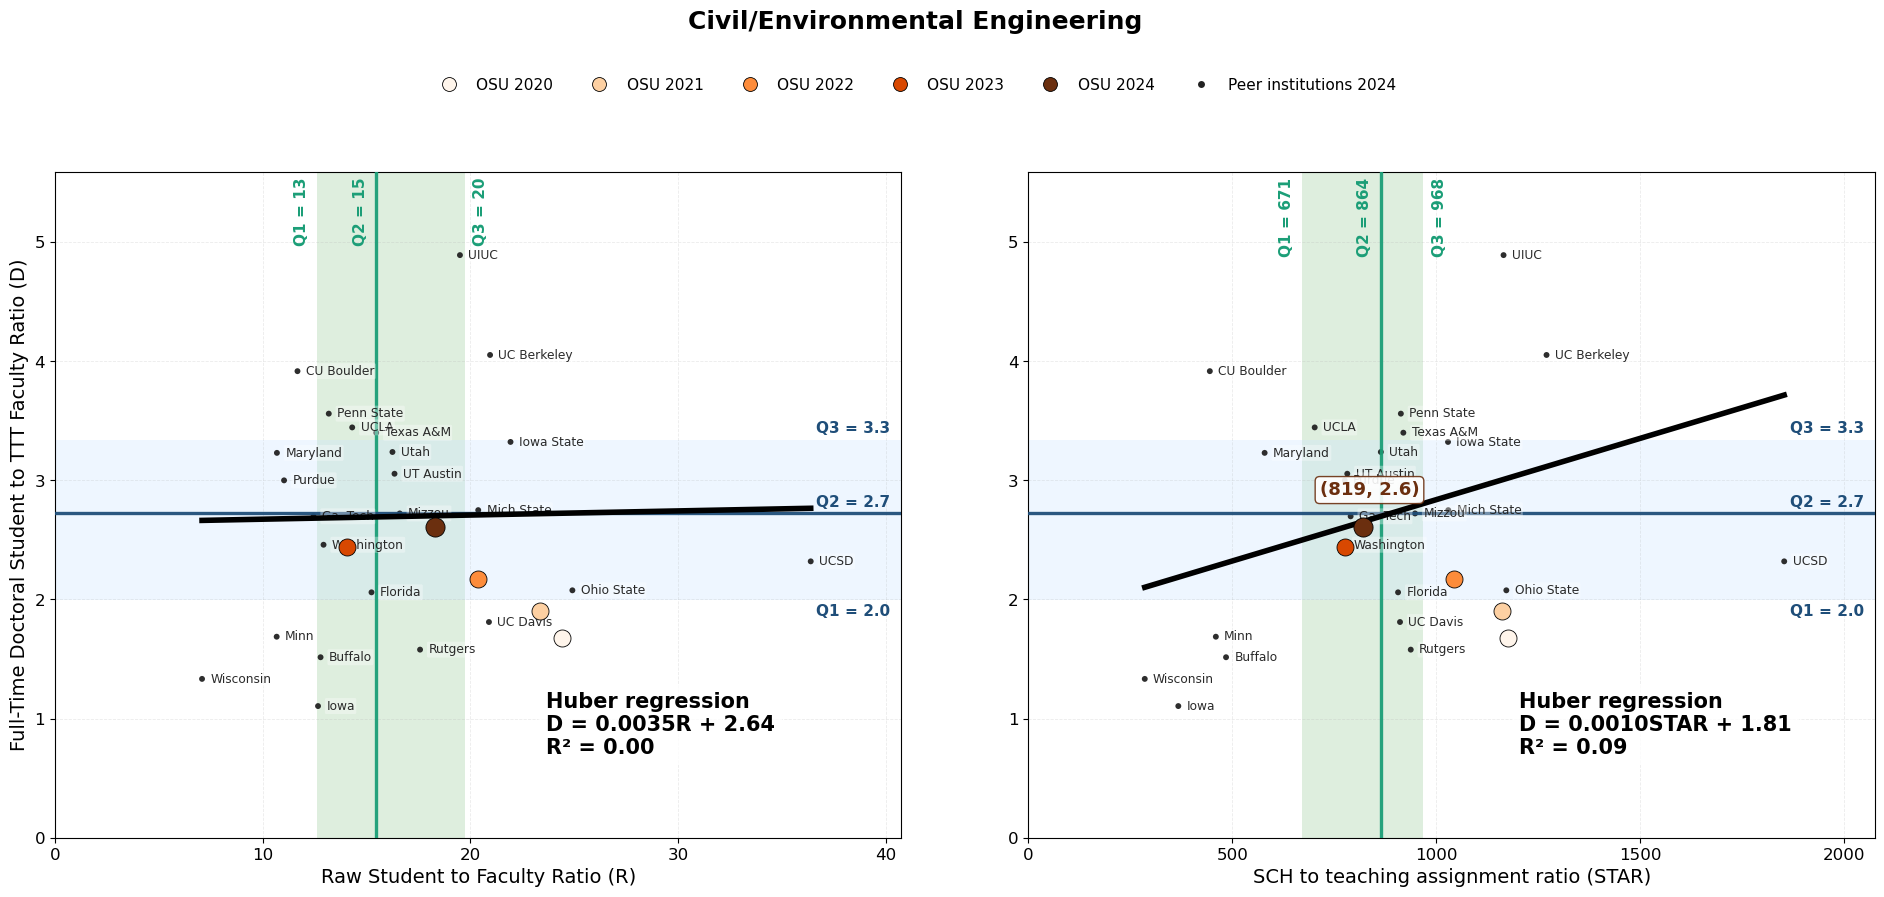

In [18]:
disc="Civil/Environmental Engineering"
plot_disc(disc, multiply=500)

In [27]:
# df_prepared_all.to_excel('prepared_faculty_data.xlsx', index=False)

## Computer Science (inside engineering)

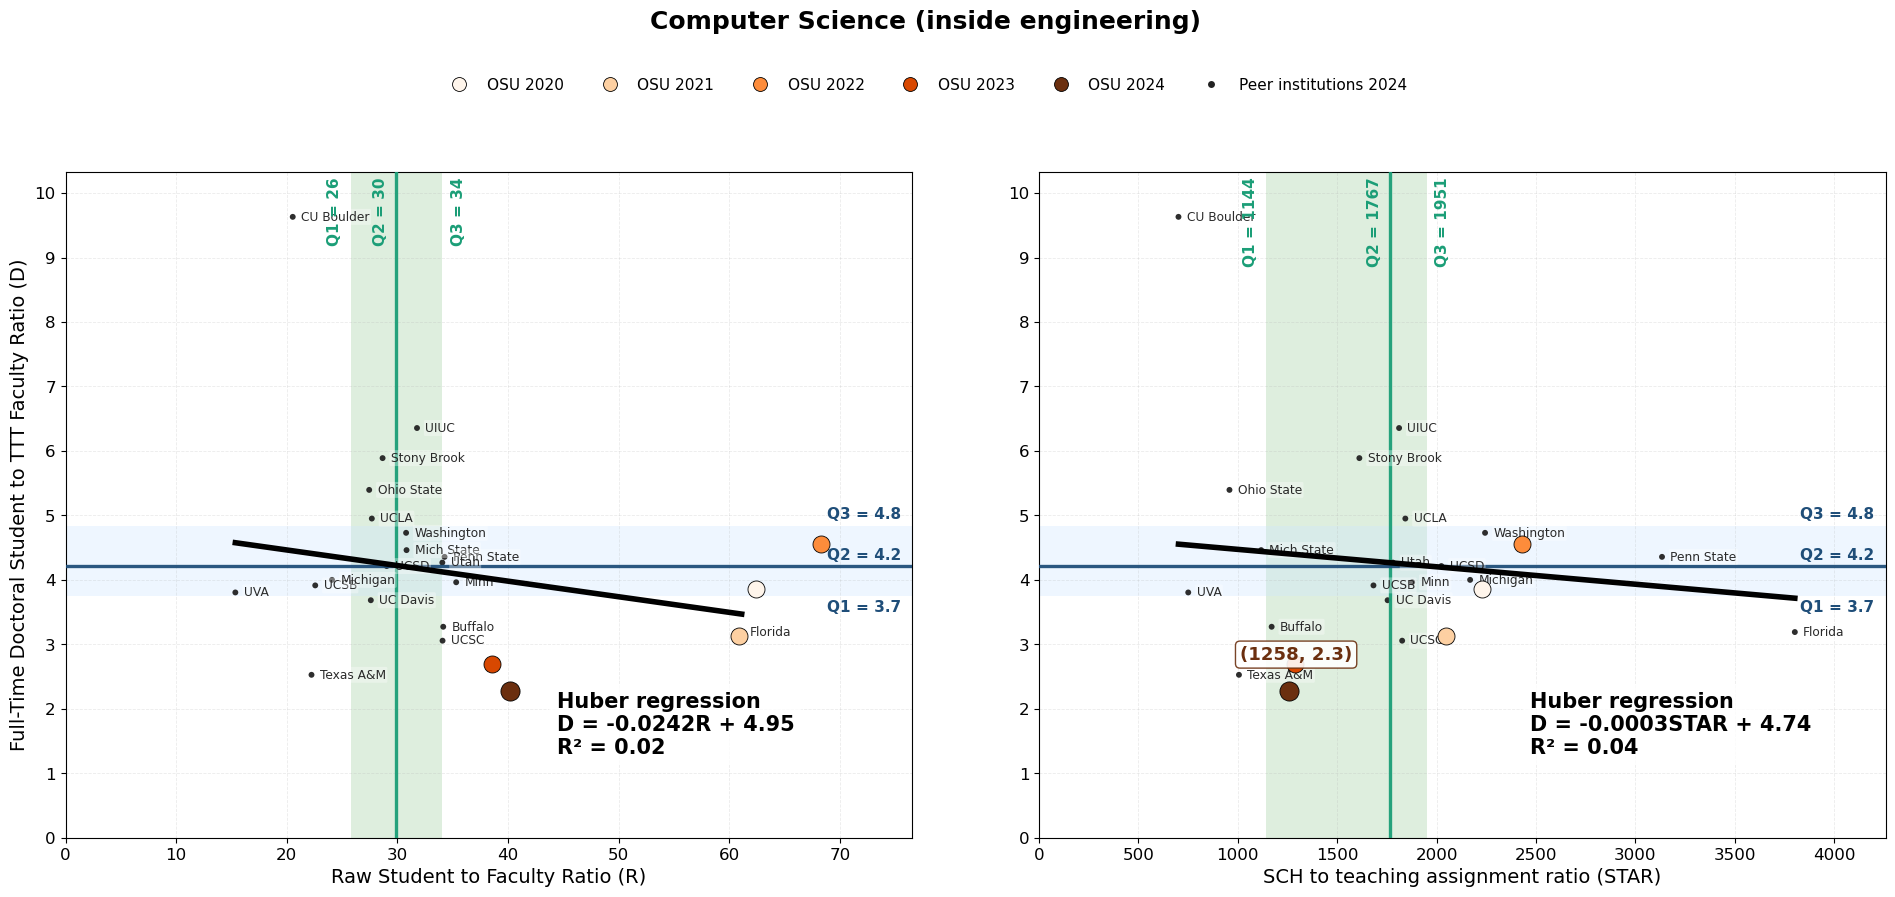

In [19]:
disc="Computer Science (inside engineering)"
plot_disc(disc, multiply=500)

## Electrical/Computer Engineering

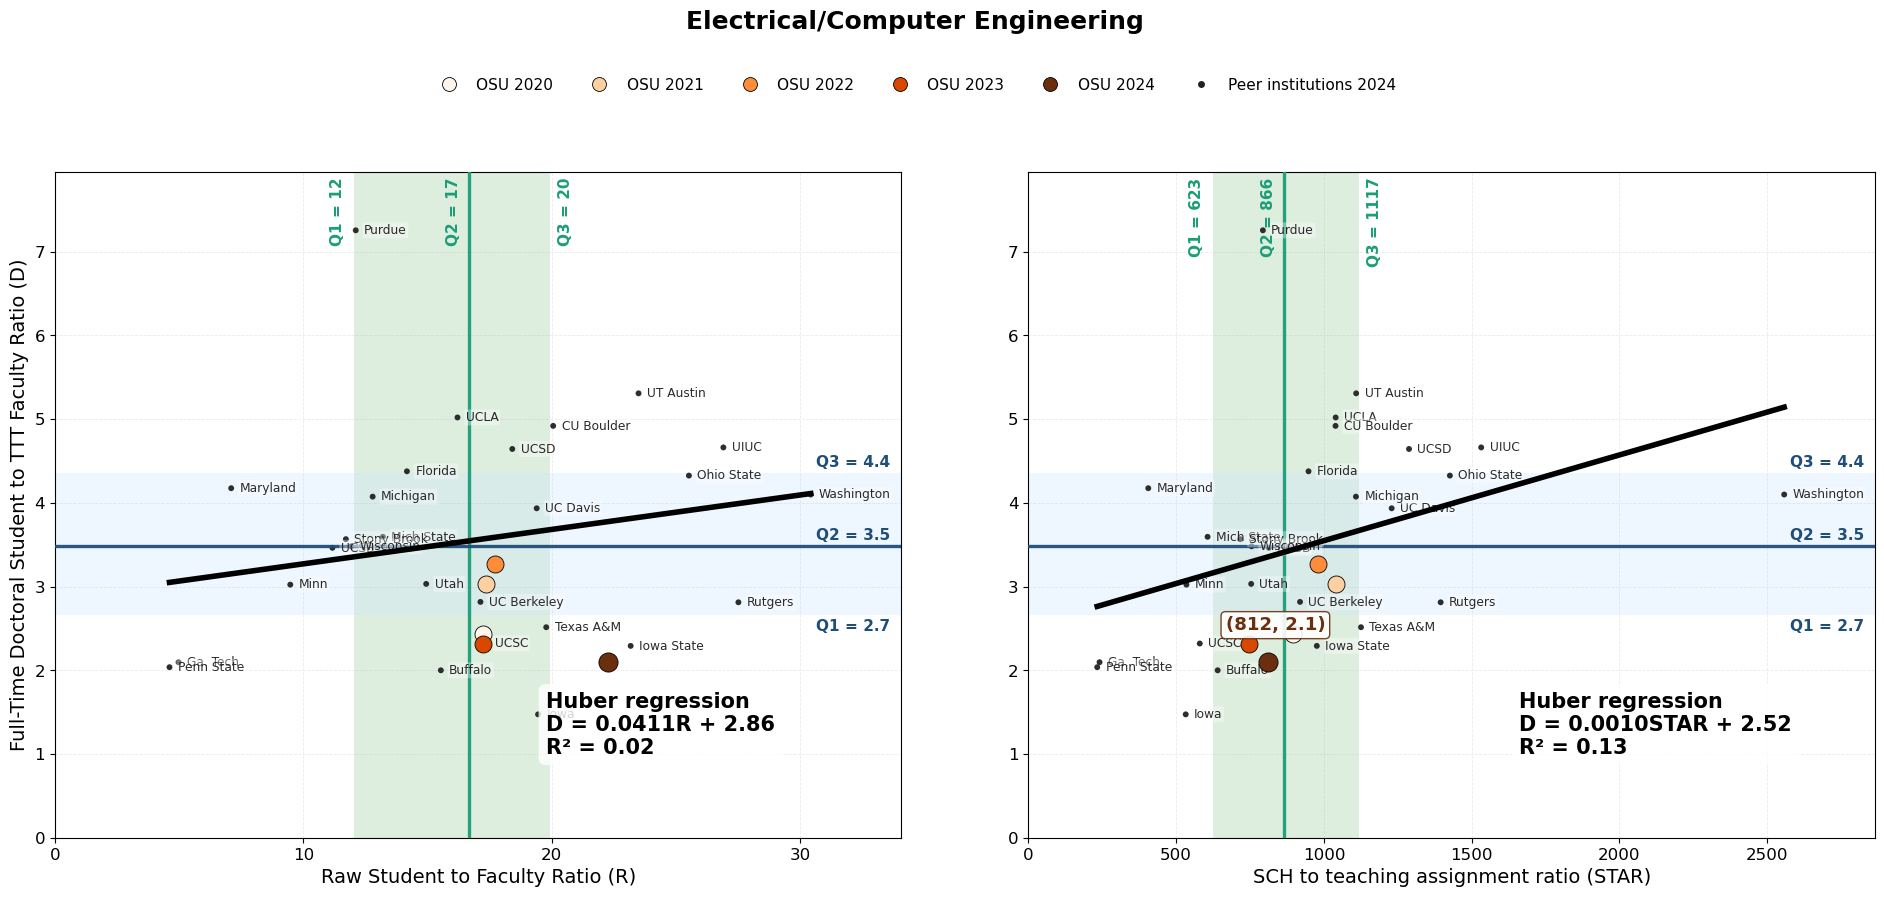

In [53]:
disc="Electrical/Computer Engineering"
plot_disc(disc, multiply=500)

## Chemical Engineering

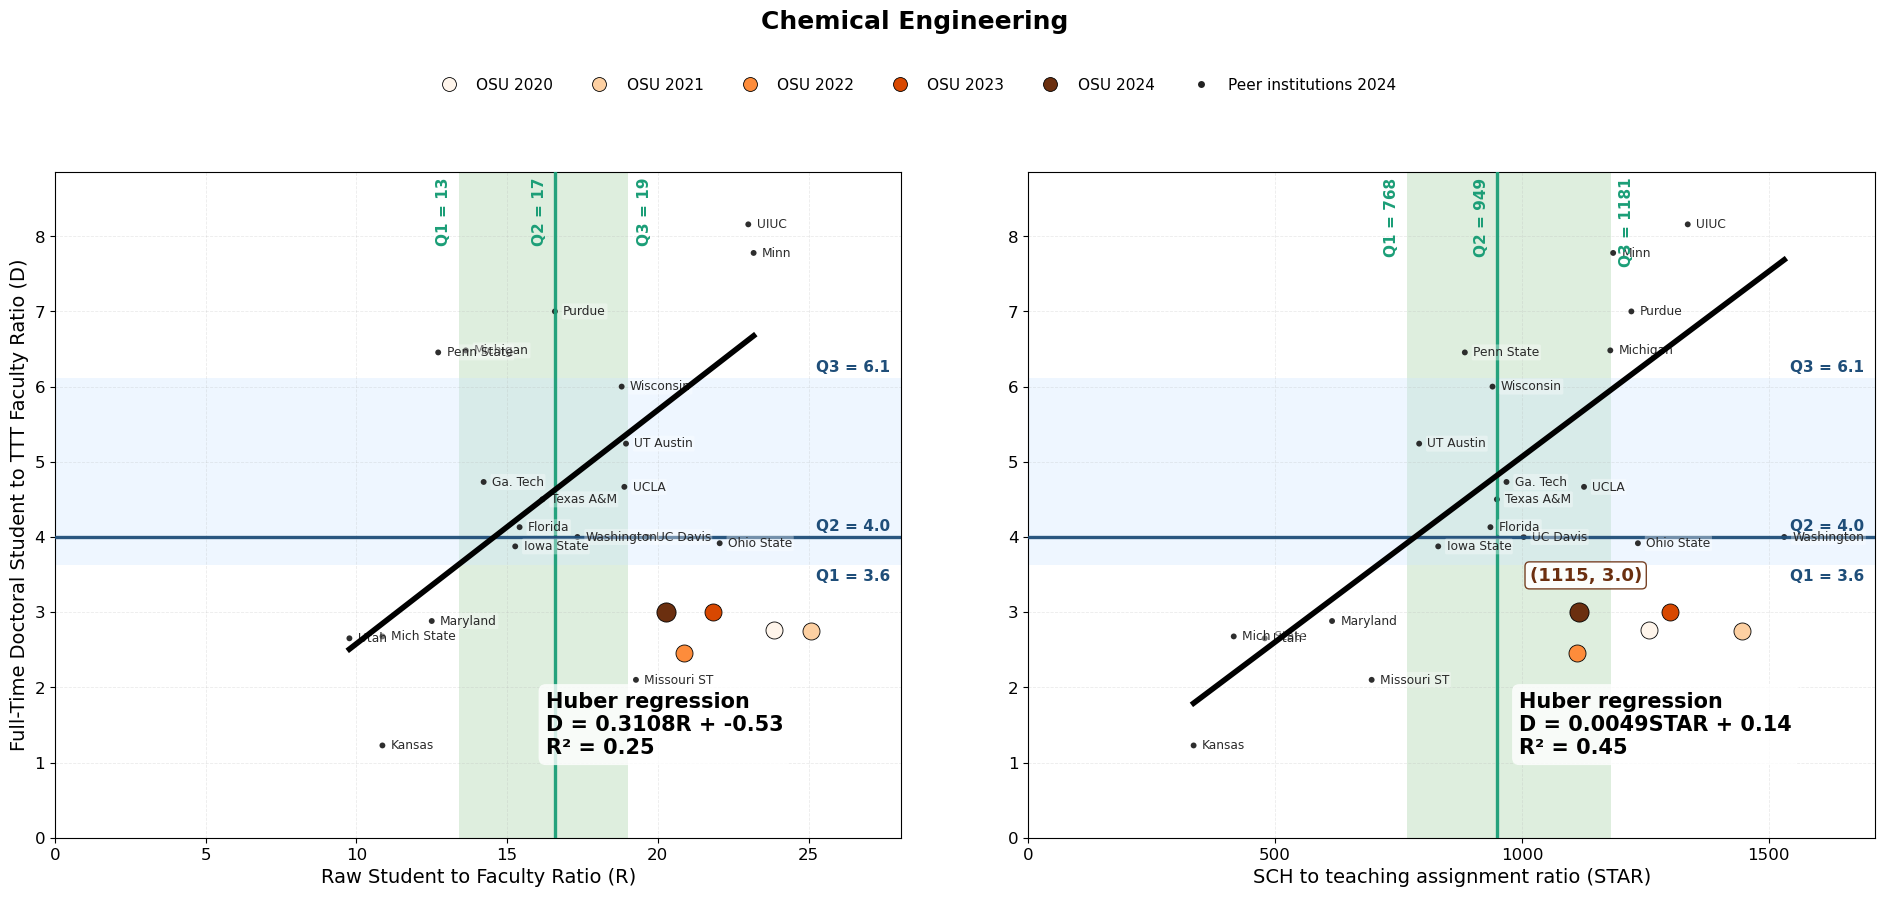

In [54]:
disc="Chemical Engineering"
plot_disc(disc, multiply=500)

## Mechanical Engineering

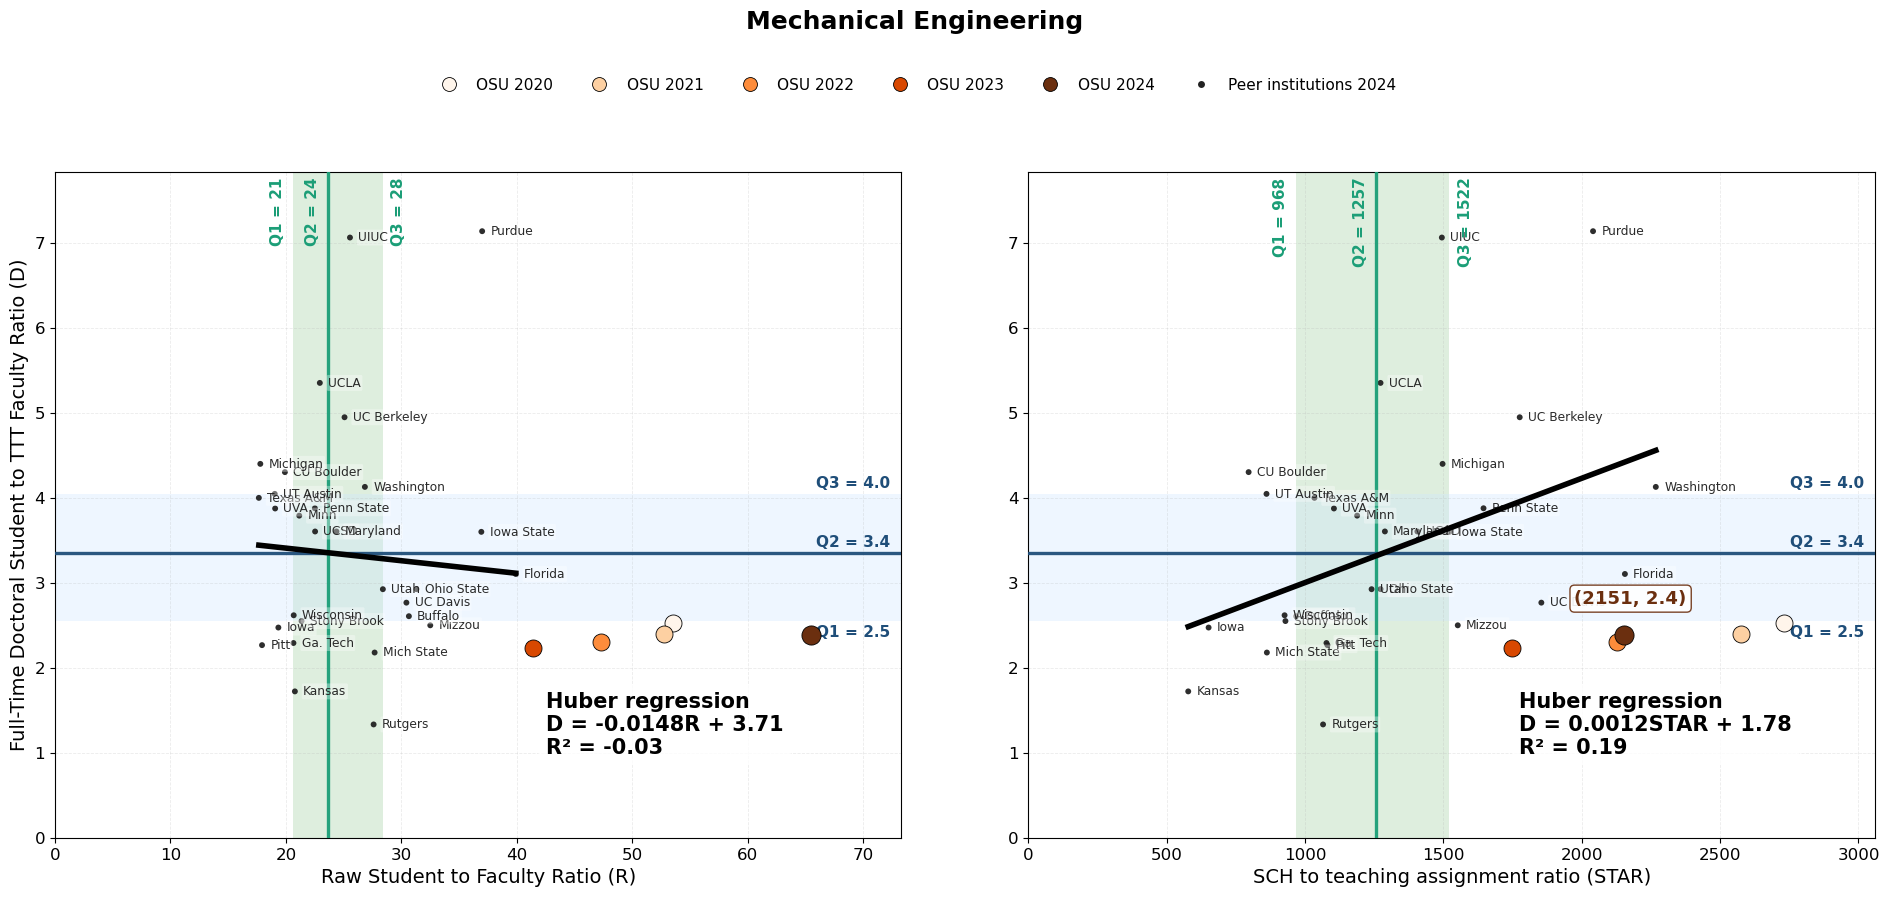

In [55]:
disc="Mechanical Engineering"
plot_disc(disc, multiply=500)

## Biomedical Engineering

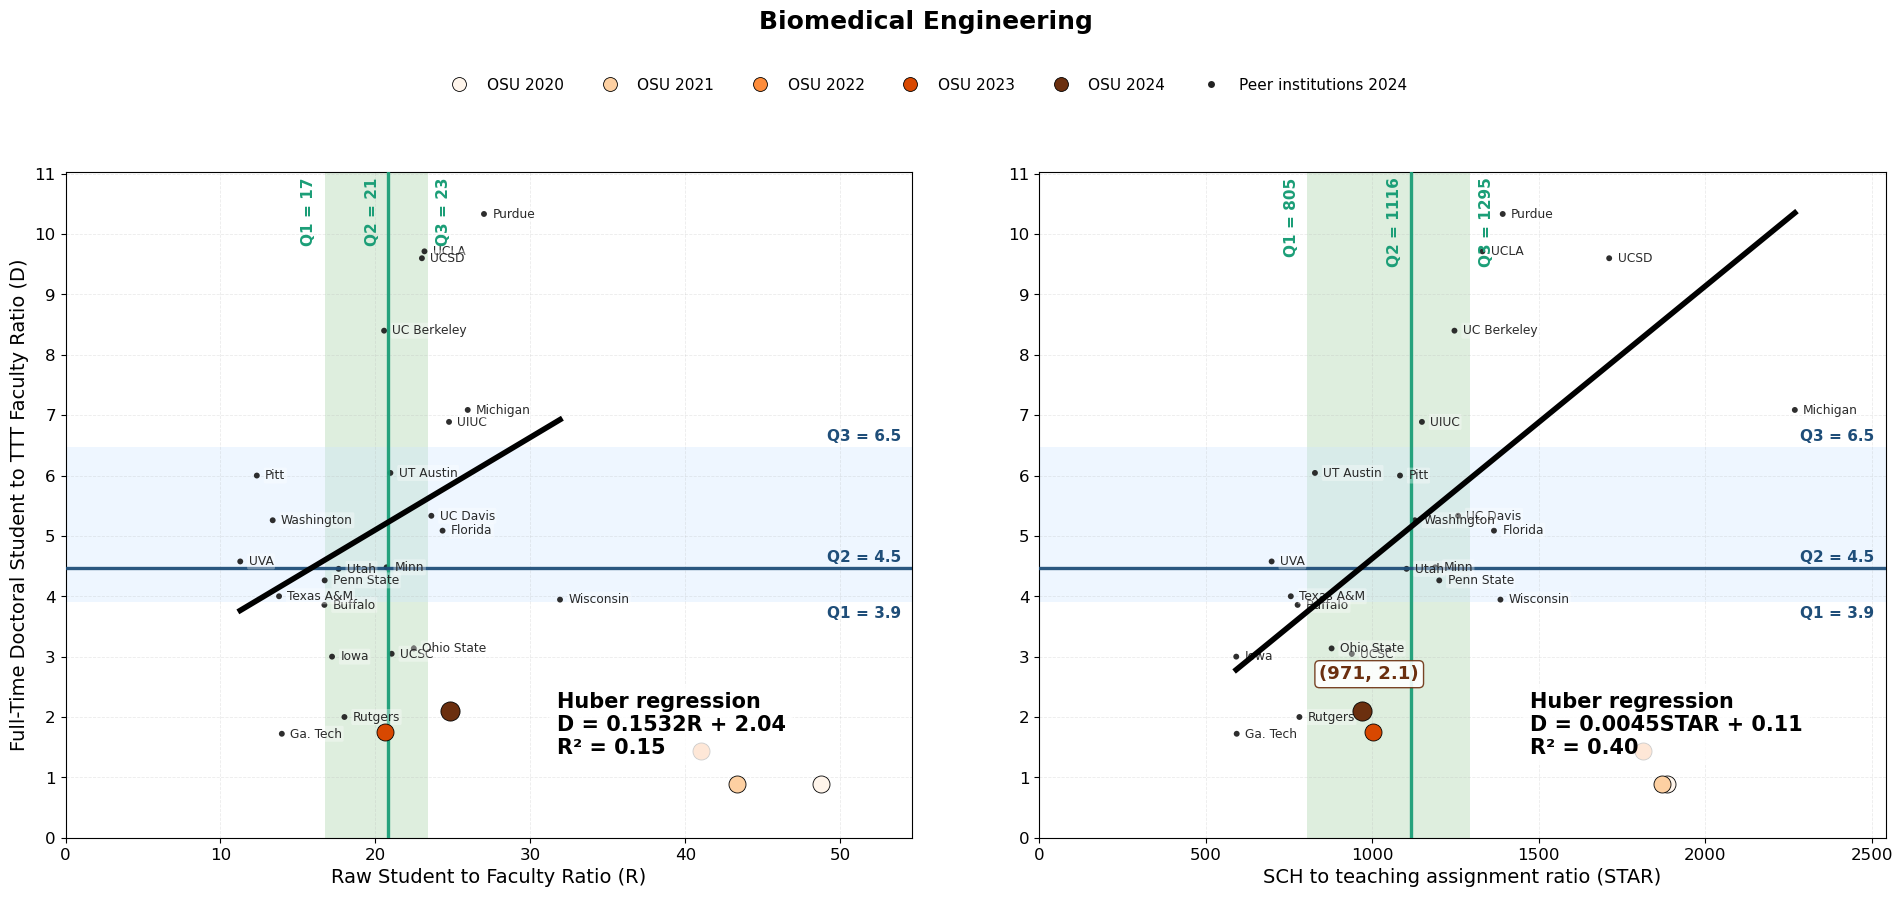

In [56]:
disc="Biomedical Engineering"
plot_disc(disc, multiply=500)

### Nuclear Engineering

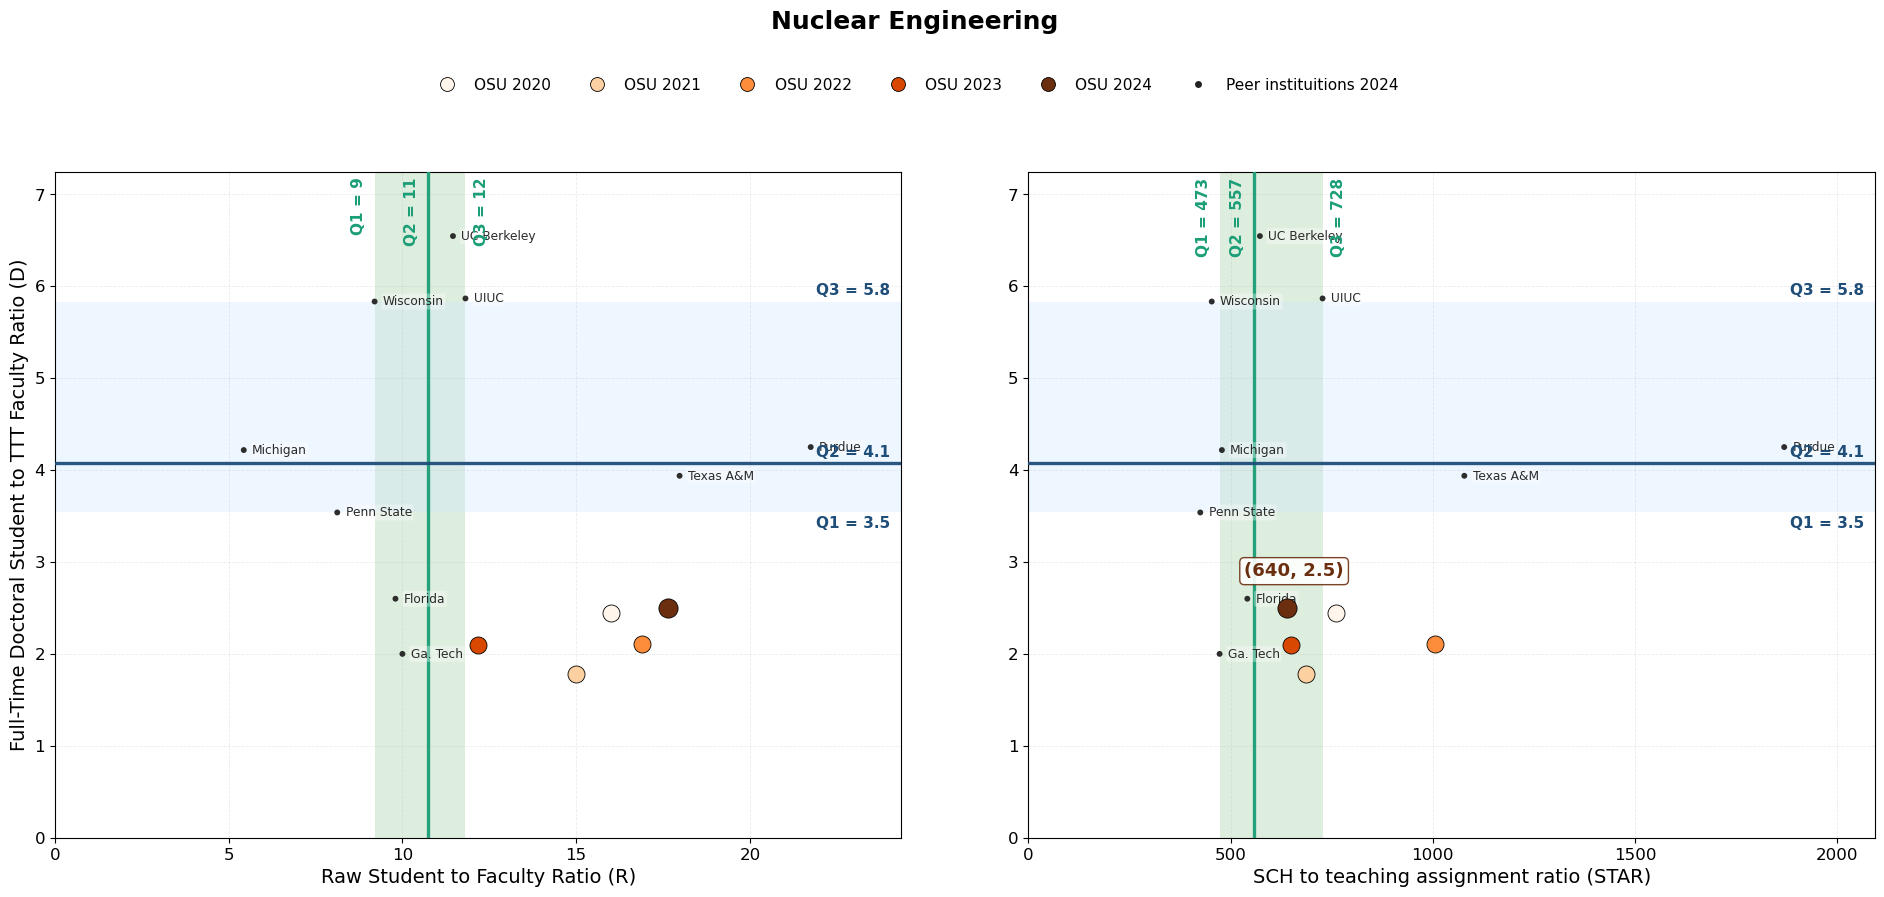

In [40]:
short_name_path="../Data/AAU Publics 1.xlsx"
raw_data = pd.read_excel('../Data/raw_data_v3.xlsx')
df_prepared_all = prepapre_data(raw_data, 49, 4, 4)

df_prepared_all = add_short_names(
        df_prepared_all,
        short_name_path=short_name_path
    )

df_osu = df_prepared_all[
    df_prepared_all["School Name"] == "Oregon State University"
].copy()
    
df_other = df_prepared_all[
    df_prepared_all["School Name"] != "Oregon State University"
].copy()


    
disc = "Nuclear Engineering"   
plot(
    disc=disc,
    df_osu=df_osu,
    df_other=df_other,
    latest_peer_year=2024,
    multiply=500
)

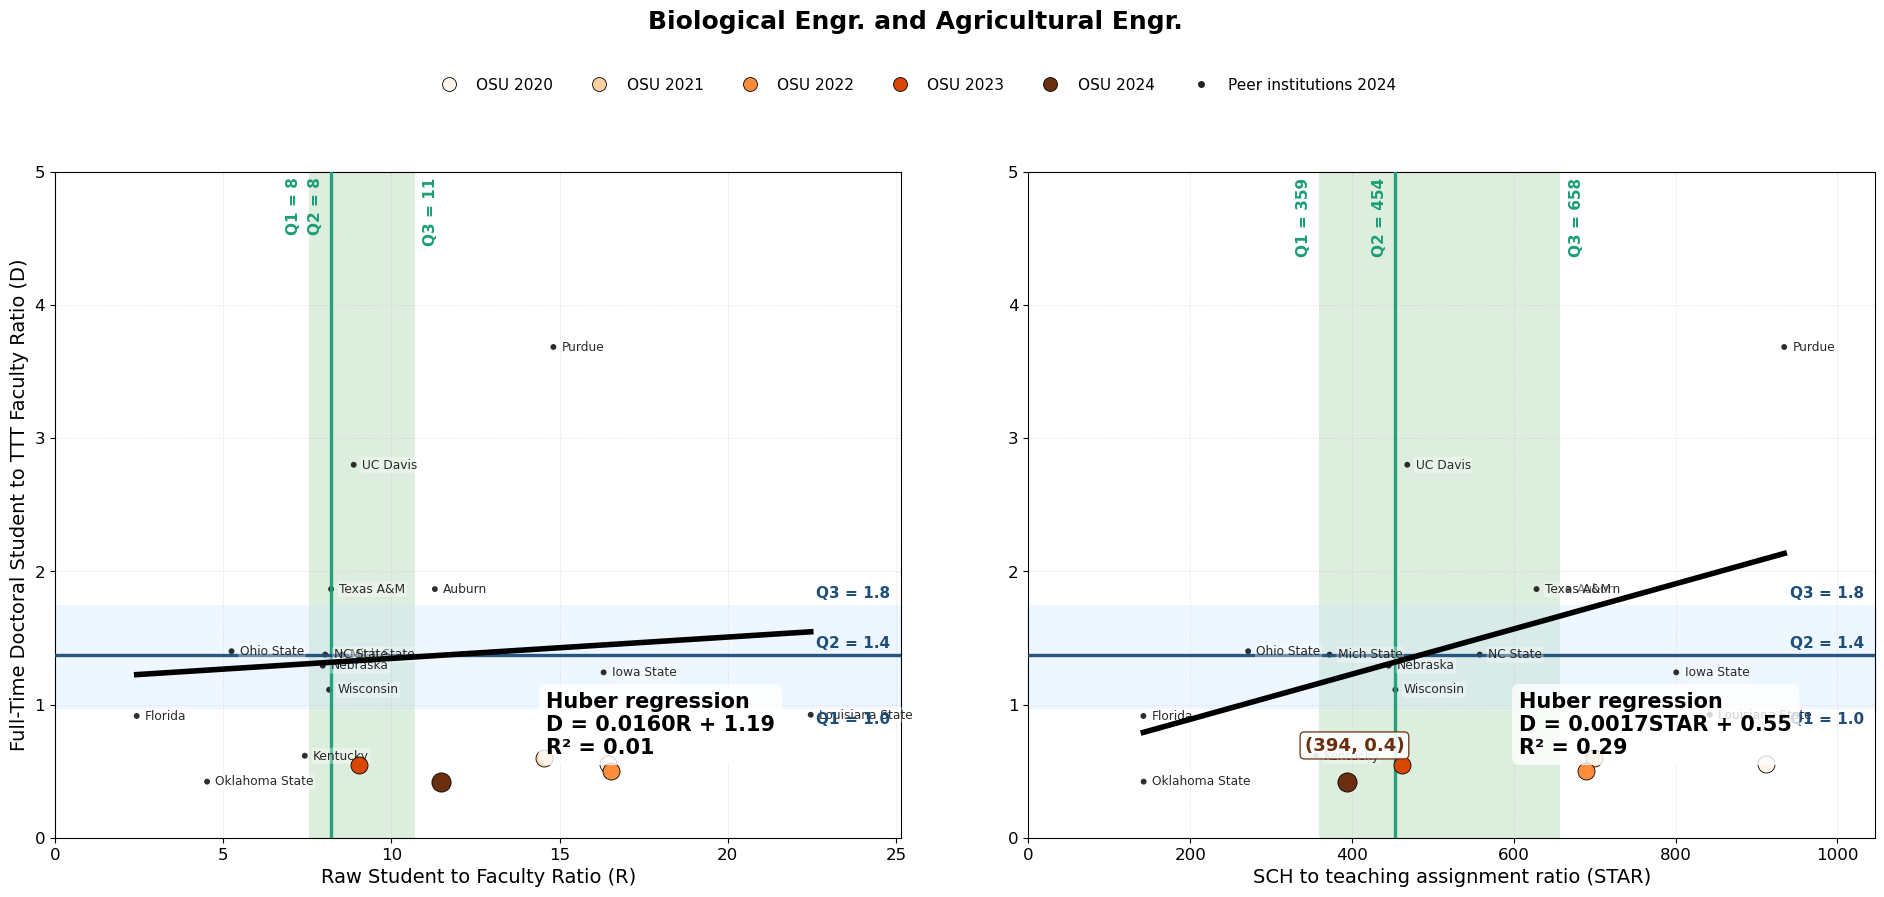

In [59]:
short_name_path="../Data/AAU Publics 1.xlsx"
raw_data = pd.read_excel('../Data/raw_data_v3.xlsx')
df_prepared_all = prepapre_data(raw_data, 49, 4, 4)

df_prepared_all = add_short_names(
        df_prepared_all,
        short_name_path=short_name_path
    )

df_osu = df_prepared_all[
    df_prepared_all["School Name"] == "Oregon State University"
].copy()
    
df_other = df_prepared_all[
    df_prepared_all["School Name"] != "Oregon State University"
].copy()
    
disc = "Biological Engr. and Agricultural Engr."   
plot(
    disc=disc,
    df_osu=df_osu,
    df_other=df_other,
    latest_peer_year=2024,
    multiply=200,
    add_regression='Y'
)

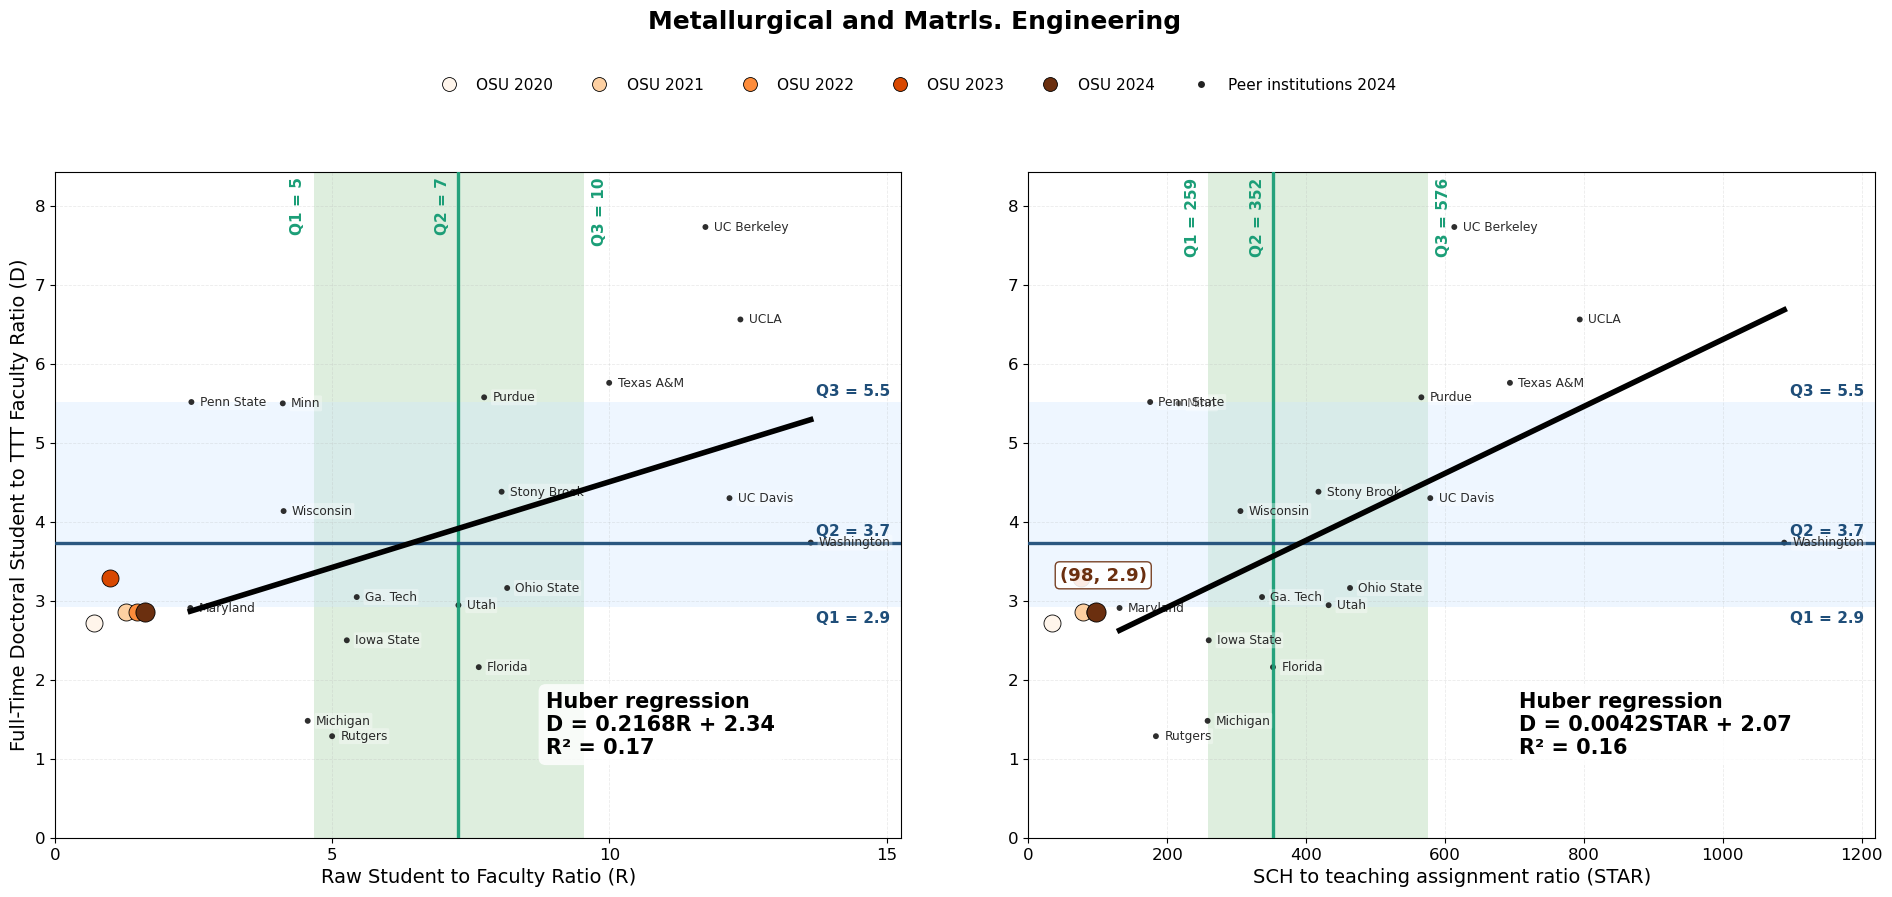

In [60]:
raw_data = pd.read_excel('../Data/raw_data_v3.xlsx')
df_prepared_all = prepapre_data(raw_data, 49, 4, 4)

df_prepared_all = add_short_names(
        df_prepared_all,
        short_name_path=short_name_path
    )

df_osu = df_prepared_all[
    df_prepared_all["School Name"] == "Oregon State University"
].copy()
    
df_other = df_prepared_all[
    df_prepared_all["School Name"] != "Oregon State University"
].copy()
    
disc = "Metallurgical and Matrls. Engineering"   
plot(
    disc=disc,
    df_osu=df_osu,
    df_other=df_other,
    latest_peer_year=2024,
    multiply=200,
    add_regression='Y'
)

#### Industrial/Manufacturing/Systems Engineering

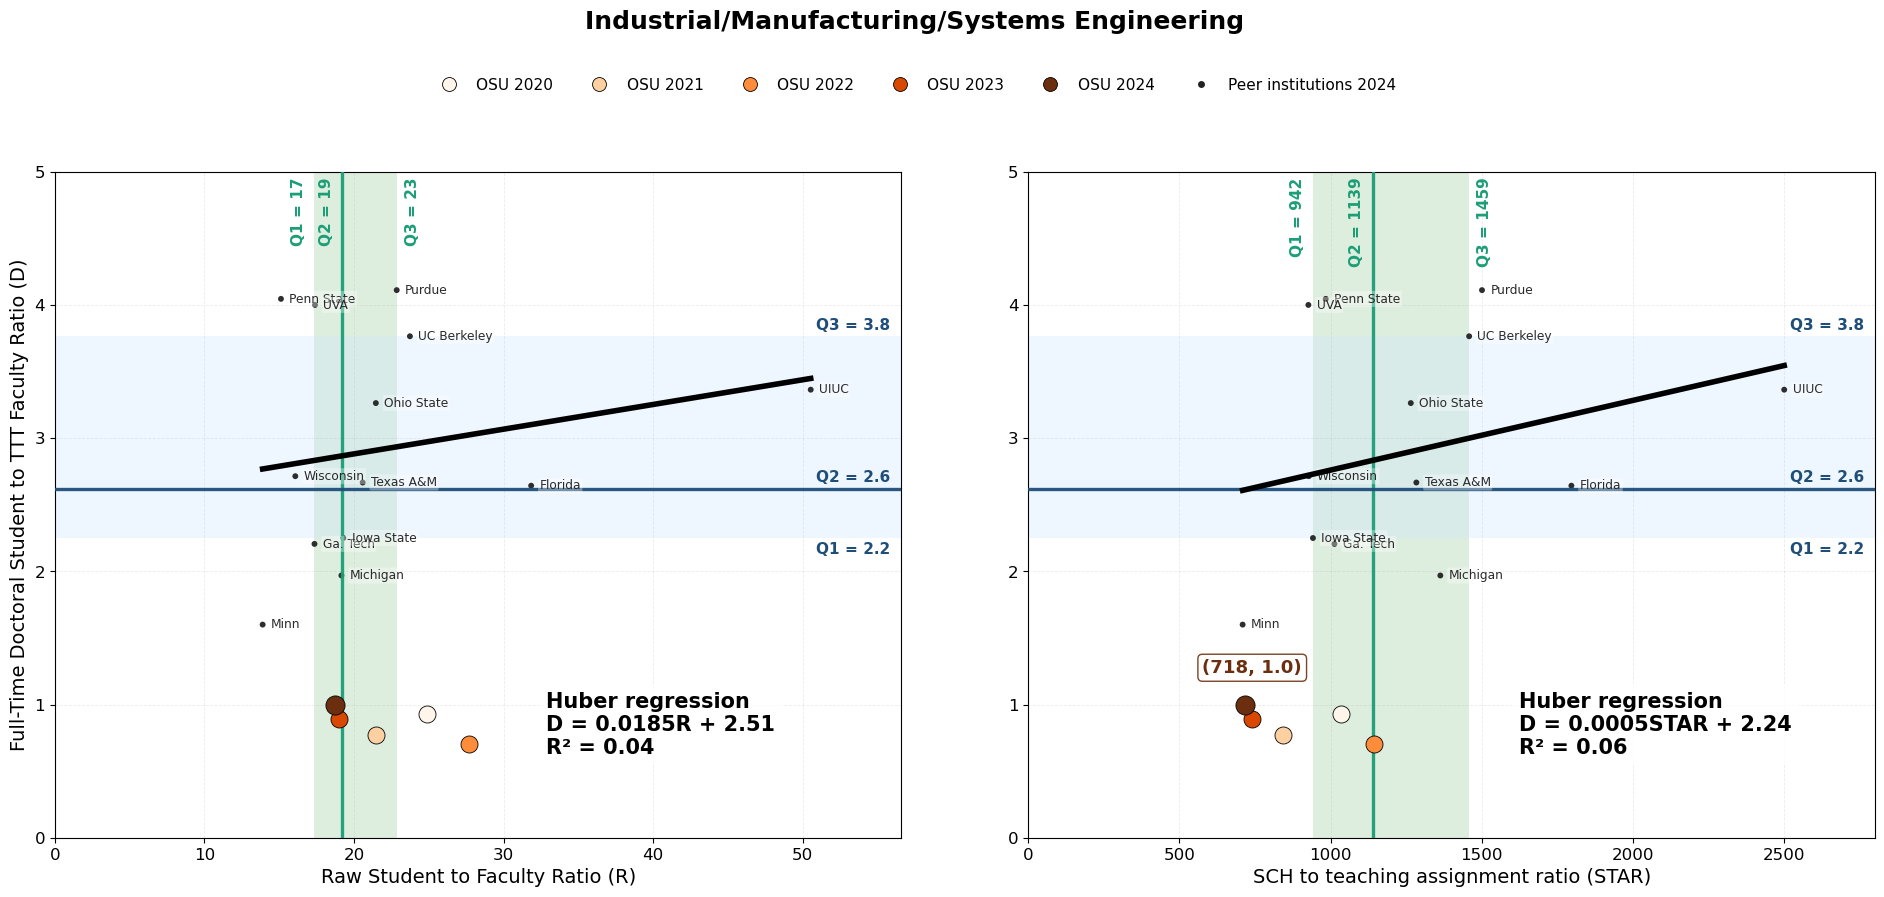

In [61]:
disc = 'Industrial/Manufacturing/Systems Engineering'
plot_disc(disc, multiply=500)

In [13]:
PROGRAM_THRESHOLDS = {
    # Larger programs
    "Civil/Environmental Engineering": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },
    "Computer Science (inside engineering)": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },
    "Electrical/Computer Engineering": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },
    "Chemical Engineering": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },
    "Mechanical Engineering": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },
    "Biomedical Engineering": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },
    "Industrial/Manufacturing/Systems Engineering": {
        "ug_ft": 199,
        "phd_ft": 9,
        "ttt": 9
    },

    # Smaller programs
    "Nuclear Engineering": {
        "ug_ft": 49,
        "phd_ft": 4,
        "ttt": 4
    },
    "Metallurgical and Matrls. Engineering": {
        "ug_ft": 49,
        "phd_ft": 4,
        "ttt": 4
    },
    "Biological Engr. and Agricultural Engr.": {
        "ug_ft": 49,
        "phd_ft": 4,
        "ttt": 4
    },
}

In [14]:
# sorted(raw_data["Discipline Name"].dropna().unique())

In [15]:
def build_threshold_based_s_d_tables(
    raw_data,
    program_thresholds,
    latest_peer_year=2024,
    osu_name="Oregon State University"
):
    """
    Builds threshold-based S and D summary tables.

    Important:
    Q1/Q2/Q3 and z-score benchmark distributions are calculated including OSU,
    matching the benchmark logic in prepapre_data(), where S_AAU / D_AAU are
    calculated from the full prepared dataset rather than peer-only.

    For each program:
      1. Apply that program's ug_ft, phd_ft, and ttt thresholds through prepapre_data().
      2. Keep the selected discipline.
      3. Use all institutions, including OSU, for Q1/Q2/Q3 and z-score benchmark distribution.
      4. Report OSU's latest-year S and D separately.
      5. Report OSU's S and D z-scores relative to the benchmark-year distribution.
    """

    combined_rows = []

    for disc, thresholds in program_thresholds.items():
        ug_ft = thresholds["ug_ft"]
        phd_ft = thresholds["phd_ft"]
        ttt = thresholds["ttt"]

        # Recalculate prepared metrics using discipline-specific thresholds
        df_prepared = prepapre_data(
            raw_data,
            ug_ft=ug_ft,
            phd_ft=phd_ft,
            ttt=ttt
        )

        df_disc = df_prepared[
            df_prepared["Discipline Name"] == disc
        ].copy()

        if df_disc.empty:
            print(f"Skipping {disc}: no rows found after threshold-based preparation.")
            continue

        # --------------------------------------------------------------
        # Benchmark distribution for Q1/Q2/Q3 and z-scores
        #
        # IMPORTANT:
        # Include OSU here so Q2 matches S_AAU / D_AAU logic.
        # --------------------------------------------------------------
        df_benchmark = df_disc[
            df_disc["Year"] == latest_peer_year
        ].copy()

        df_osu_disc = df_disc[
            df_disc["School Name"] == osu_name
        ].copy()

        if df_benchmark.empty:
            print(f"Skipping {disc}: no benchmark rows found for {latest_peer_year}.")
            continue

        if df_osu_disc.empty:
            print(f"Skipping {disc}: no OSU rows found.")
            continue

        # Clean numeric columns
        for col in ["S", "D", "S_AAU", "D_AAU"]:
            if col in df_benchmark.columns:
                df_benchmark[col] = pd.to_numeric(df_benchmark[col], errors="coerce")

            if col in df_osu_disc.columns:
                df_osu_disc[col] = pd.to_numeric(df_osu_disc[col], errors="coerce")

        df_benchmark = df_benchmark.dropna(subset=["S", "D"])
        df_osu_disc = df_osu_disc.dropna(subset=["S", "D"])

        if df_benchmark.empty or df_osu_disc.empty:
            print(f"Skipping {disc}: missing valid S/D values.")
            continue

        # Latest available OSU year
        osu_latest_year = int(df_osu_disc["Year"].max())

        df_osu_latest = df_osu_disc[
            df_osu_disc["Year"] == osu_latest_year
        ].copy()

        # --------------------------------------------------------------
        # S percentiles including OSU
        # --------------------------------------------------------------
        s_q1 = np.nanpercentile(df_benchmark["S"], 25)
        s_q2 = np.nanpercentile(df_benchmark["S"], 50)
        s_q3 = np.nanpercentile(df_benchmark["S"], 75)

        # --------------------------------------------------------------
        # D percentiles including OSU
        # --------------------------------------------------------------
        d_q1 = np.nanpercentile(df_benchmark["D"], 25)
        d_q2 = np.nanpercentile(df_benchmark["D"], 50)
        d_q3 = np.nanpercentile(df_benchmark["D"], 75)

        # --------------------------------------------------------------
        # OSU values
        # --------------------------------------------------------------
        osu_s = float(df_osu_latest["S"].median())
        osu_d = float(df_osu_latest["D"].median())

        # --------------------------------------------------------------
        # Benchmark means and standard deviations including OSU
        # --------------------------------------------------------------
        s_mean = df_benchmark["S"].mean()
        s_std = df_benchmark["S"].std(ddof=0)

        d_mean = df_benchmark["D"].mean()
        d_std = df_benchmark["D"].std(ddof=0)

        # --------------------------------------------------------------
        # OSU z-scores
        #
        # z = (OSU value - benchmark mean) / benchmark standard deviation
        # If std is 0 or missing, return NaN to avoid division errors.
        # --------------------------------------------------------------
        osu_s_z = (osu_s - s_mean) / s_std if pd.notna(s_std) and s_std != 0 else np.nan
        osu_d_z = (osu_d - d_mean) / d_std if pd.notna(d_std) and d_std != 0 else np.nan

        combined_rows.append({
            "Program": disc,
            "UG FT Threshold": ug_ft,
            "PhD FT Threshold": phd_ft,
            "TTT Threshold": ttt,
            "Benchmark Year": latest_peer_year,
            "OSU Year": osu_latest_year,

            "S Q1": int(round(s_q1)),
            "S Q2": int(round(s_q2)),
            "S Q3": int(round(s_q3)),
            "OSU S": int(round(osu_s)),
            "OSU S Z-Score": round(osu_s_z, 2) if pd.notna(osu_s_z) else np.nan,

            "D Q1": round(d_q1, 1),
            "D Q2": round(d_q2, 1),
            "D Q3": round(d_q3, 1),
            "OSU D": round(osu_d, 1),
            "OSU D Z-Score": round(osu_d_z, 2) if pd.notna(osu_d_z) else np.nan,
        })

    combined_table = pd.DataFrame(combined_rows)

    s_table = combined_table[
        [
            "Program",
            "UG FT Threshold",
            "PhD FT Threshold",
            "TTT Threshold",
            "Benchmark Year",
            "OSU Year",
            "S Q1",
            "S Q2",
            "S Q3",
            "OSU S",
            "OSU S Z-Score"
        ]
    ].copy()

    d_table = combined_table[
        [
            "Program",
            "UG FT Threshold",
            "PhD FT Threshold",
            "TTT Threshold",
            "Benchmark Year",
            "OSU Year",
            "D Q1",
            "D Q2",
            "D Q3",
            "OSU D",
            "OSU D Z-Score"
        ]
    ].copy()

    return s_table, d_table, combined_table

In [11]:
raw_data = pd.read_excel("../Data/raw_data_v3.xlsx")

s_table, d_table, combined_table = build_threshold_based_s_d_tables(
    raw_data=raw_data,
    program_thresholds=PROGRAM_THRESHOLDS,
    latest_peer_year=2024
)

s_table

,Program,UG FT Threshold,PhD FT Threshold,TTT Threshold,Benchmark Year,OSU Year,S Q1,S Q2,S Q3,OSU S,OSU S Z-Score
0,Civil/Environmental Engineering,199,9,9,2024,2024,702,864,948,819,-0.09
1,Computer Science (inside engineering),199,9,9,2024,2024,1157,1767,1914,1258,-0.63
2,Electrical/Computer Engineering,199,9,9,2024,2024,632,866,1113,812,-0.26
3,Chemical Engineering,199,9,9,2024,2024,792,949,1179,1115,0.57
4,Mechanical Engineering,199,9,9,2024,2024,984,1257,1544,2151,1.86
5,Biomedical Engineering,199,9,9,2024,2024,817,1116,1277,971,-0.38
6,Industrial/Manufacturing/Systems Engineering,199,9,9,2024,2024,931,1139,1435,718,-1.13
7,Nuclear Engineering,49,4,4,2024,2024,474,557,706,640,-0.20
8,Metallurgical and Matrls. Engineering,49,4,4,2024,2024,237,352,572,98,-1.30
9,Biological Engr. and Agricultural Engr.,49,4,4,2024,2024,364,454,648,394,-0.45


In [27]:
combined_table

,Program,UG FT Threshold,PhD FT Threshold,TTT Threshold,Benchmark Year,OSU Year,S Q1,S Q2,S Q3,OSU S,OSU S Z-Score,D Q1,D Q2,D Q3,OSU D,OSU D Z-Score
0,Civil/Environmental Engineering,199,9,9,2024,2024,702,864,948,819,-0.09,2.1,2.7,3.3,2.6,-0.11
1,Computer Science (inside engineering),199,9,9,2024,2024,1157,1767,1914,1258,-0.63,3.6,4.1,4.8,2.3,-1.36
2,Electrical/Computer Engineering,199,9,9,2024,2024,632,866,1113,812,-0.26,2.5,3.5,4.3,2.1,-1.15
3,Chemical Engineering,199,9,9,2024,2024,792,949,1179,1115,0.57,3.0,4.1,6.0,3.0,-0.84
4,Mechanical Engineering,199,9,9,2024,2024,984,1257,1544,2151,1.86,2.5,3.4,4.0,2.4,-0.82
5,Biomedical Engineering,199,9,9,2024,2024,817,1116,1277,971,-0.38,3.7,4.5,6.3,2.1,-1.29
6,Industrial/Manufacturing/Systems Engineering,199,9,9,2024,2024,931,1139,1435,718,-1.13,2.2,2.7,3.7,1.0,-1.96
7,Nuclear Engineering,49,4,4,2024,2024,474,557,706,640,-0.20,2.8,4.1,5.4,2.5,-1.11
8,Metallurgical and Matrls. Engineering,49,4,4,2024,2024,237,352,572,98,-1.30,2.9,3.7,5.5,2.9,-0.65
9,Biological Engr. and Agricultural Engr.,49,4,4,2024,2024,364,454,648,394,-0.45,0.9,1.3,1.6,0.4,-1.19


In [26]:
combined_table.to_excel('S_D_tables_with_z_score.xlsx')

### All the star plots, with Consistent Y-Axis

In [24]:
import re

def clean_sheet_name(name):
    name = re.sub(r'[\[\]\:\*\?\/\\]', "_", str(name))
    return name[:31]


def export_simulation_data_by_program(
    raw_df,
    program_thresholds,
    output_path="simulation_input_data_by_program.xlsx"
):
    with pd.ExcelWriter(output_path, engine="xlsxwriter") as writer:

        for program, thresholds in program_thresholds.items():

            # Filter raw data to one discipline first
            df_program_raw = raw_df[
                raw_df["Discipline Name"] == program
            ].copy()

            if df_program_raw.empty:
                continue

            # Apply your existing preparation function using program-specific thresholds
            df_program_prepared = prepapre_data(
                df_program_raw,
                ug_ft=thresholds["ug_ft"],
                phd_ft=thresholds["phd_ft"],
                ttt=thresholds["ttt"]
            )

            # Optional: keep only useful columns for your boss
            cols_to_export = [
                "Discipline Name",
                "School Name",
                "Year",

                "Freshman Full Time Sum",
                "Sophomore Full Time Sum",
                "Junior Full Time Sum",
                "Senior Full Time Sum",
                "Freshman Part Time Sum",
                "Sophomore Part Time Sum",
                "Junior Part Time Sum",
                "Senior Part Time Sum",
                "Masters Full Time Sum",
                "Masters Part Time Sum",
                "Doctoral Full Time Sum",

                "Total Tenured/Tenure-Track Faculty",
                "Full Time Teaching Faculty (Non-Tenure)",
                "FTE of Part Time Teaching Faculty (Non-Tenure)",

                "UG_FT_R",
                "UG_PT_R",
                "UG_FT_S",
                "UG_PT_S",
                "MS_FT",
                "MS_PT",
                "TTT",
                "NTT",

                "D",
                "D_AAU",
                "alpha",

                "R_raw_num",
                "R_raw_den",
                "R_raw",
                "R_AAU",

                "SCH",
                "S_den",
                "S",
                "S_AAU"
            ]

            cols_to_export = [
                c for c in cols_to_export
                if c in df_program_prepared.columns
            ]

            export_df = df_program_prepared[cols_to_export].copy()

            # Sort for readability
            export_df = export_df.sort_values(
                ["Year", "School Name"],
                ascending=[True, True]
            )

            sheet_name = clean_sheet_name(program)

            export_df.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False
            )

            # Formatting
            workbook = writer.book
            worksheet = writer.sheets[sheet_name]

            header_format = workbook.add_format({
                "bold": True,
                "text_wrap": True,
                "valign": "top",
                "bg_color": "#D9EAF7",
                "border": 1
            })

            number_format = workbook.add_format({
                "num_format": "0.000"
            })

            integer_format = workbook.add_format({
                "num_format": "0"
            })

            # Header format
            for col_num, value in enumerate(export_df.columns):
                worksheet.write(0, col_num, value, header_format)

            # Freeze top row
            worksheet.freeze_panes(1, 0)

            # Add filter
            worksheet.autofilter(
                0,
                0,
                len(export_df),
                len(export_df.columns) - 1
            )

            # Column widths
            for i, col in enumerate(export_df.columns):
                width = min(
                    max(export_df[col].astype(str).map(len).max(), len(col)) + 2,
                    35
                )
                worksheet.set_column(i, i, width)

            # Numeric formatting
            for i, col in enumerate(export_df.columns):
                if col in ["D", "D_AAU", "alpha", "R_raw", "R_AAU", "S", "S_AAU"]:
                    worksheet.set_column(i, i, 12, number_format)

                if col in ["Year", "SCH"]:
                    worksheet.set_column(i, i, 12, integer_format)

    return output_path

In [29]:
raw_data = pd.read_excel('../Data/raw_data_v3.xlsx')
export_simulation_data_by_program(
    raw_df=raw_data,
    program_thresholds=PROGRAM_THRESHOLDS,
    output_path="simulation_input_data_by_program.xlsx"
)

'simulation_input_data_by_program.xlsx'

In [28]:
# !pip install xlsxwriter